# Module 5 Lab 2: Textbook Problem 5.3 

Sequoia Ridgeway

CS 82A

Github Portfolio: https://github.com/ridgewaysequoia9/cs82a-portfolio

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the tab-seperated customer dataset
df = pd.read_csv("custdata.tsv", sep="\t")

# Check the total rows and inspect housing.type including missing values
print("Total rows before cleaning:", len(df))
print("\nHousing type counts ( including missing):")
print(df["housing.type"].value_counts(dropna=False))

Total rows before cleaning: 1000

Housing type counts ( including missing):
housing.type
Homeowner with mortgage/loan    412
Rented                          364
Homeowner free and clear        157
NaN                              56
Occupied with no rent            11
Name: count, dtype: int64


In [2]:
# Count missing housing.type rows before dropping 
excluded_rows = df["housing.type"].isna().sum()

# Drop rows where housing.type is missing
df_clean = df.dropna(subset=["housing.type"])

# Count remaining customers per housing type (sorted highest to lowest)
housing_counts = df_clean["housing.type"].value_counts()

print("Rows excluded (NA housing.type):", excluded_rows)
print("Rows remaining after cleaning:", len(df_clean))
print("\nCleaned housing type counts:")
print(housing_counts)

Rows excluded (NA housing.type): 56
Rows remaining after cleaning: 944

Cleaned housing type counts:
housing.type
Homeowner with mortgage/loan    412
Rented                          364
Homeowner free and clear        157
Occupied with no rent            11
Name: count, dtype: int64


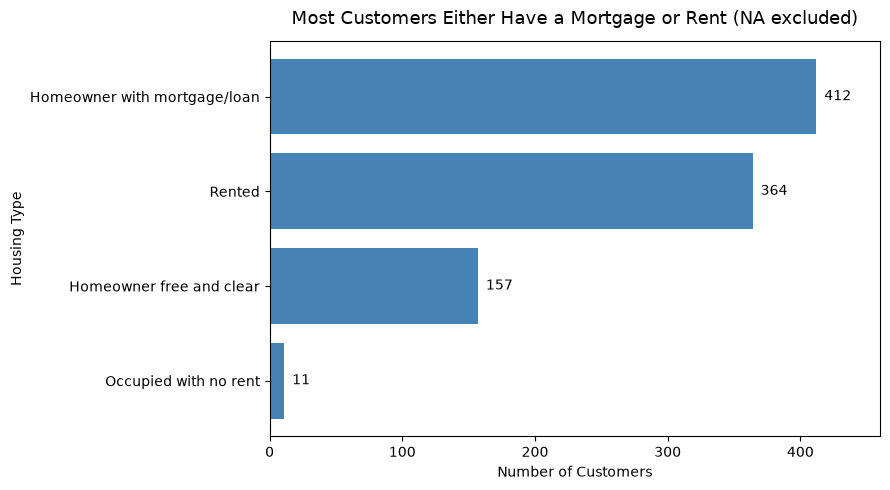

In [3]:
# Sort ascending so the largest category appears at the top of the horizontal bar chart
housing_counts_sorted = housing_counts.sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(housing_counts_sorted.index, housing_counts_sorted.values, color="steelblue")

# Add exact counts at the end of each bar
for bar in bars:
    width = bar.get_width()
    ax.text(width + 6, bar.get_y() + bar.get_height() / 2, f"{int(width)}", va="center")

# Takeaway title and labeled axes
ax.set_title("Most Customers Either Have a Mortgage or Rent (NA excluded)", fontsize=13, pad=12)
ax.set_xlabel("Number of Customers")
ax.set_ylabel("Housing Type")
ax.set_xlim(0, 460)

plt.tight_layout()
plt.show()

**Data Cleaning Note**: So, 56 rows were excluded from this chart because they had missing values in the `housing.type` column, leaving 944 customer records out of the original 1,000.